# StudyNest — analysis

**Research question:** does iOS-style vs Android-style presentation of the *same* deceptive free-trial offer change trust, detection of the hidden terms, and behaviour?

Extends Li, Flatla & Arndt (2025), *Divergent deceptions*, Behaviour & Information Technology 44(16).

> ⚠️ Until real data exists this notebook runs on **synthetic data** from `make_fake_data.py`. Change `DATA` below to your export (full JSON preferred, or the summary CSV), or to `"--firestore"`.

**Pre-registered rules**
* Exclusions (in `load_data.py`): demo, status ≠ complete, `task_total_ms` < 15 000, IDs in `pilot_ids.txt`.
* `detected` = final coding is **detected** (strict). `partly` counts as not detected; a lenient variant is reported in the descriptives. Declining alone is *not* evidence of detection.
* All main tests run on manipulation-check passes, then again on all complete sessions.
* With ~7–10 per condition, estimates are uncertain; a non-significant result does **not** establish equivalence.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats.contingency import odds_ratio
from statsmodels.stats.proportion import proportion_confint
import statsmodels.formula.api as smf

from load_data import load, load_raw, apply_exclusions, load_sessions_json

DATA = "data/fake_sessions.json"   # ← your export: e.g. "data/studynest_full_2026-11-20.json"
RNG = np.random.default_rng(2026)
LABEL = {"ios": "iOS style", "md": "Android style"}

raw = load_raw(DATA)
df = load(DATA)
print(f"{len(raw)} sessions in file → {len(df)} after exclusions")
df.groupby("condition").size().rename("n").to_frame()

44 sessions in file → 40 after exclusions


,n
condition,
ios,20
md,20


## Coding reliability (open-ended detection answers)

In [2]:
coding = pd.read_csv("detection_coding.csv")
coding = coding[coding["id"].isin(df["id"])]
agree = (coding["coder1"] == coding["coder2"]).mean()
print(f"Percent agreement coder1 vs coder2: {agree:.1%} (n = {len(coding)})")
pd.crosstab(coding["coder1"], coding["coder2"], margins=True)

Percent agreement coder1 vs coder2: 87.5% (n = 40)


coder2,detected,not,partly,All
coder1,,,,
detected,12,0,0,12
not,2,14,1,17
partly,2,0,9,11
All,16,14,10,40


## Helpers

In [3]:
def rank_biserial(a, b):
    """r = 2·U_a/(n_a·n_b) − 1; positive means `a` tends to be larger."""
    u = stats.mannwhitneyu(a, b, alternative="two-sided").statistic
    return 2 * u / (len(a) * len(b)) - 1

def boot_ci(a, b, fn=rank_biserial, n=2000):
    a, b = np.asarray(a), np.asarray(b)
    vals = [fn(RNG.choice(a, len(a)), RNG.choice(b, len(b))) for _ in range(n)]
    return np.nanpercentile(vals, [2.5, 97.5])

def mwu(d, col):
    a = d.loc[d.condition == "ios", col].dropna().astype(float)
    b = d.loc[d.condition == "md", col].dropna().astype(float)
    if len(a) < 2 or len(b) < 2:
        return {"measure": col, "note": "too few observations"}
    res = stats.mannwhitneyu(a, b, alternative="two-sided")
    lo, hi = boot_ci(a, b)
    return {"measure": col, "n_ios": len(a), "n_md": len(b), "median_ios": a.median(), "median_md": b.median(),
            "U": res.statistic, "p": res.pvalue, "r_rb": rank_biserial(a, b), "r_CI": f"[{lo:.2f}, {hi:.2f}]"}

def wilson(k, n):
    lo, hi = proportion_confint(k, n, method="wilson") if n else (np.nan, np.nan)
    return f"{k}/{n} = {k / n:.0%} [{lo:.0%}, {hi:.0%}]" if n else "—"

def fisher_2x2(table):
    table = np.asarray(table, dtype=int)
    p = stats.fisher_exact(table).pvalue
    try:
        orr = odds_ratio(table)
        ci = orr.confidence_interval()
        return p, orr.statistic, (ci.low, ci.high)
    except Exception:
        return p, np.nan, (np.nan, np.nan)

## Hypothesis tests

In [4]:
def run_all(d, title):
    print("=" * 78, f"\n{title}  (n = {len(d)}: iOS {sum(d.condition == 'ios')}, Android {sum(d.condition == 'md')})\n" + "=" * 78)

    # H1 — trust differs
    h1 = mwu(d, "trust_mean")
    print("\nH1 trust (Mann–Whitney U, rank-biserial r with bootstrap 95% CI)")
    display(pd.DataFrame([h1]))

    # H2 — susceptibility differs
    tab = pd.crosstab(d.condition, d.susceptible.astype(bool)).reindex(index=["ios", "md"], columns=[True, False], fill_value=0)
    p, orr, ci = fisher_2x2(tab.values)
    print("\nH2 susceptibility (Fisher's exact; Wilson 95% CI)")
    for c in ["ios", "md"]:
        print(f"  {LABEL[c]:14} susceptible {wilson(int(tab.loc[c, True]), int(tab.loc[c].sum()))}")
    print(f"  Fisher p = {p:.3f}, odds ratio (iOS vs Android) = {orr:.2f}, 95% CI [{ci[0]:.2f}, {ci[1]:.2f}]")

    # H3 — attention differs
    print("\nH3 attention (Mann–Whitney U)")
    display(pd.DataFrame([mwu(d, c) for c in ["disclosure_visible_ms", "paywall_dwell_ms", "decision_latency_ms"]]))
    print("  View-details taps (count of participants with ≥1 / total taps):")
    for c in ["ios", "md"]:
        g = d[d.condition == c]
        print(f"    {LABEL[c]:14} {(g.view_details_taps > 0).sum()}/{len(g)} participants, {int(g.view_details_taps.sum())} taps")

    # H4 — safety belief vs detection
    dd = d.dropna(subset=["detected"])
    t4 = pd.crosstab(dd.believes_safer == "ios", dd.detected.astype(bool)).reindex(index=[True, False], columns=[True, False], fill_value=0)
    p4, or4, ci4 = fisher_2x2(t4.values)
    print("\nH4 believes iOS is safer × detected (Fisher's exact)")
    print(f"  believes iOS safer: detected {wilson(int(t4.loc[True, True]), int(t4.loc[True].sum()))}")
    print(f"  others:             detected {wilson(int(t4.loc[False, True]), int(t4.loc[False].sum()))}")
    print(f"  p = {p4:.3f}, OR = {or4:.2f}, 95% CI [{ci4[0]:.2f}, {ci4[1]:.2f}]")

    # H5 — visibility predicts detection
    print("\nH5 logistic regression: detected ~ disclosure_visible_s + C(condition) + C(own_platform)")
    m = dd.assign(detected=dd.detected.astype(int), disclosure_visible_s=dd.disclosure_visible_ms / 1000)
    try:
        import warnings
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fit = smf.logit("detected ~ disclosure_visible_s + C(condition) + C(own_platform)", data=m).fit(disp=False, maxiter=200)
        if not fit.mle_retvals.get("converged", False):
            print("  Model did not converge (likely (quasi-)separation with this sample size) — report descriptively instead.")
            print(m.groupby(["condition", "detected"]).disclosure_visible_s.median().unstack().round(1).to_string())
            return
        summ = pd.DataFrame({"coef": fit.params, "OR": np.exp(fit.params), "p": fit.pvalues})
        display(summ.join(np.exp(fit.conf_int()).rename(columns={0: "OR 2.5%", 1: "OR 97.5%"})))
    except Exception as e:  # small samples often separate perfectly
        print(f"  Model could not be estimated: {e}")

passes = df[df.manip_pass == True]
run_all(passes, "MAIN: manipulation-check passes only")

MAIN: manipulation-check passes only  (n = 35: iOS 16, Android 19)



H1 trust (Mann–Whitney U, rank-biserial r with bootstrap 95% CI)


,measure,n_ios,n_md,median_ios,median_md,U,p,r_rb,r_CI
0,trust_mean,16,19,3.9,3.4,182.0,0.326025,0.197368,"[-0.19, 0.59]"



H2 susceptibility (Fisher's exact; Wilson 95% CI)
  iOS style      susceptible 8/16 = 50% [28%, 72%]
  Android style  susceptible 10/19 = 53% [32%, 73%]
  Fisher p = 1.000, odds ratio (iOS vs Android) = 0.90, 95% CI [0.20, 4.14]

H3 attention (Mann–Whitney U)


,measure,n_ios,n_md,median_ios,median_md,U,p,r_rb,r_CI
0,disclosure_visible_ms,16,19,5451.0,5978.0,123.5,0.353803,-0.187500,"[-0.55, 0.19]"
1,paywall_dwell_ms,16,19,9157.0,10013.0,115.0,0.226803,-0.243421,"[-0.60, 0.16]"
2,decision_latency_ms,16,19,5469.5,6002.0,124.0,0.362464,-0.184211,"[-0.54, 0.22]"


  View-details taps (count of participants with ≥1 / total taps):
    iOS style      1/16 participants, 1 taps
    Android style  3/19 participants, 3 taps

H4 believes iOS is safer × detected (Fisher's exact)
  believes iOS safer: detected 5/18 = 28% [12%, 51%]
  others:             detected 6/17 = 35% [17%, 59%]
  p = 0.725, OR = 0.71, 95% CI [0.13, 3.70]

H5 logistic regression: detected ~ disclosure_visible_s + C(condition) + C(own_platform)
  Model did not converge (likely (quasi-)separation with this sample size) — report descriptively instead.
detected     0     1
condition           
ios        4.5  16.1
md         5.3  19.4


In [5]:
run_all(df, "ROBUSTNESS: all complete sessions")

ROBUSTNESS: all complete sessions  (n = 40: iOS 20, Android 20)



H1 trust (Mann–Whitney U, rank-biserial r with bootstrap 95% CI)


,measure,n_ios,n_md,median_ios,median_md,U,p,r_rb,r_CI
0,trust_mean,20,20,4.0,3.4,263.0,0.08924,0.315,"[-0.07, 0.66]"



H2 susceptibility (Fisher's exact; Wilson 95% CI)
  iOS style      susceptible 10/20 = 50% [30%, 70%]
  Android style  susceptible 10/20 = 50% [30%, 70%]
  Fisher p = 1.000, odds ratio (iOS vs Android) = 1.00, 95% CI [0.24, 4.10]

H3 attention (Mann–Whitney U)


,measure,n_ios,n_md,median_ios,median_md,U,p,r_rb,r_CI
0,disclosure_visible_ms,20,20,5451.0,5888.5,172.5,0.465154,-0.1375,"[-0.47, 0.24]"
1,paywall_dwell_ms,20,20,9157.0,10000.0,168.0,0.394171,-0.1600,"[-0.51, 0.21]"
2,decision_latency_ms,20,20,5469.5,5916.5,173.0,0.473460,-0.1350,"[-0.49, 0.23]"


  View-details taps (count of participants with ≥1 / total taps):
    iOS style      1/20 participants, 1 taps
    Android style  3/20 participants, 3 taps

H4 believes iOS is safer × detected (Fisher's exact)
  believes iOS safer: detected 6/22 = 27% [13%, 48%]
  others:             detected 6/18 = 33% [16%, 56%]
  p = 0.738, OR = 0.76, 95% CI [0.16, 3.63]

H5 logistic regression: detected ~ disclosure_visible_s + C(condition) + C(own_platform)


,coef,OR,p,OR 2.5%,OR 97.5%
Intercept,-2.779289,0.062083,0.006210,0.008481,0.454454
C(condition)[T.md],1.050614,2.859407,0.223119,0.527496,15.500037
C(own_platform)[T.ios],-0.466490,0.627200,0.592355,0.113710,3.459506
C(own_platform)[T.other],-0.896678,0.407923,0.579471,0.017110,9.725238
disclosure_visible_s,0.166066,1.180651,0.005242,1.050725,1.326643


## Descriptives

In [6]:
# Matched (own platform = shown style) vs mismatched
platform_of = {"ios": "ios", "md": "android"}
df["matched"] = df.apply(lambda r: platform_of[r.condition] == r.own_platform, axis=1)
desc = df.groupby(["condition", "matched"]).agg(
    n=("id", "size"), trust_median=("trust_mean", "median"), susceptible=("susceptible", "mean"),
    detected=("detected", lambda s: s.astype(float).mean()), familiar_median=("familiar", "median"))
desc

n  trust_median  susceptible  detected  familiar_median
condition matched                                                          
ios       False    10           4.0     0.500000  0.200000              4.5
          True     10           4.0     0.500000  0.200000              5.0
md        False    12           3.4     0.583333  0.333333              5.0
          True      8           3.3     0.375000  0.500000              6.0

In [7]:
lenient = df.assign(detected_any=df.detection.isin(["detected", "partly"]))
lenient.groupby("condition").agg(strict=("detected", lambda s: s.astype(float).mean()), lenient=("detected_any", "mean"),
                                 manip_pass=("manip_pass", "mean"), outcomes=("outcome", lambda s: s.value_counts().to_dict()))

,strict,lenient,manip_pass,outcomes
condition,,,,
ios,0.2,0.55,0.8,"{'trial_autorenew': 8, 'declined': 5, 'closed'..."
md,0.4,0.60,0.95,"{'trial_autorenew': 8, 'trial_no_renew': 5, 'd..."


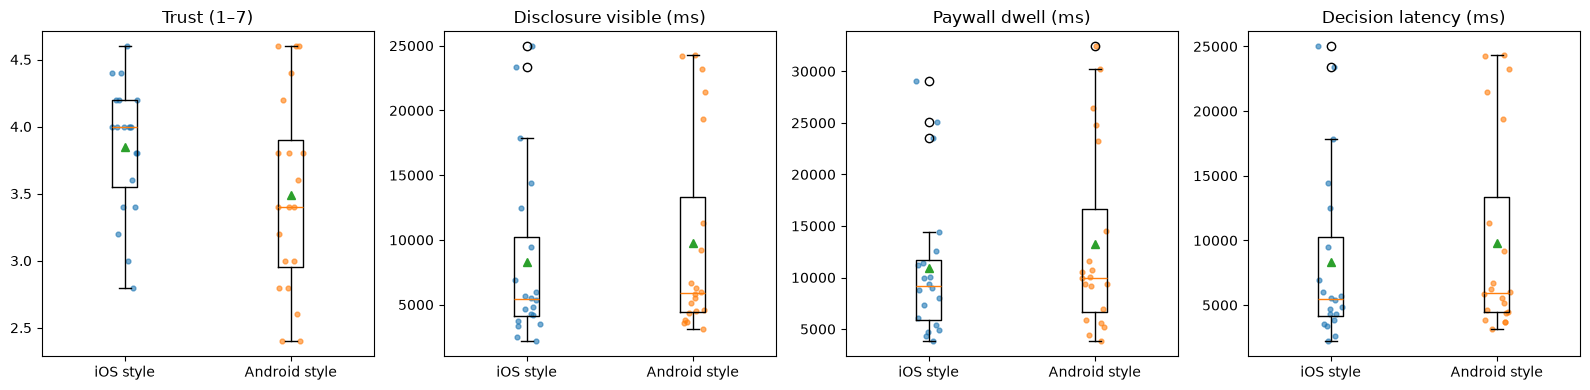

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col, lab in zip(axes, ["trust_mean", "disclosure_visible_ms", "paywall_dwell_ms", "decision_latency_ms"],
                        ["Trust (1–7)", "Disclosure visible (ms)", "Paywall dwell (ms)", "Decision latency (ms)"]):
    data = [df.loc[df.condition == c, col].dropna().astype(float) for c in ["ios", "md"]]
    ax.boxplot(data, tick_labels=[LABEL["ios"], LABEL["md"]], showmeans=True)
    for i, d in enumerate(data, 1):
        ax.scatter(np.full(len(d), i) + RNG.uniform(-0.08, 0.08, len(d)), d, s=12, alpha=0.6)
    ax.set_title(lab)
plt.tight_layout(); plt.show()

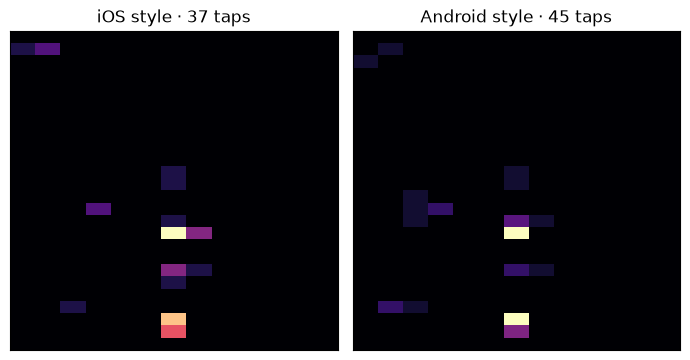

In [9]:
# Tap heatmaps on the paywall (needs the full JSON export)
if str(DATA).endswith(".json"):
    keep = set(df.id)
    taps = [(s["condition"], e["x"], e["y"]) for s in load_sessions_json(DATA) if s["id"] in keep
            for e in s["events"] if e["type"] == "tap" and e["screen"] == "paywall" and e.get("x") is not None]
    t = pd.DataFrame(taps, columns=["condition", "x", "y"])
    fig, axes = plt.subplots(1, 2, figsize=(7, 7))
    for ax, c in zip(axes, ["ios", "md"]):
        g = t[t.condition == c]
        ax.hist2d(g.x, g.y, bins=[13, 26], range=[[0, 1], [0, 1]], cmap="magma")
        ax.set_ylim(1, 0); ax.set_aspect(390 / 800 * 2); ax.set_title(f"{LABEL[c]} · {len(g)} taps")
        ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(); plt.show()
else:
    print("Tap heatmaps need the full JSON export.")